# Data to discoveries

Last time, we discussed the `NumPy` array, specifically `ndarray`. 

These are like lists in that they contain data, but an `ndarray` carries many different assumptions/restrictions.

Today, we will use two important Python packages:
- `pandas` : data wrangling 
- `MatplotLib` : data visualisation

Both are widely used with large communities.

In [2]:
import pandas as pd
print(f"pandas version: {pd.__version__}")

pandas version: 2.2.3


## Pandas DataFrame

A `DataFrame` in pandas is a data structure that is a mix between:
- Python's `dict`
- NumPy's `ndarray`

The following data comes from CSO's 2022 census data on car ownership. (I got this data from CSO a few years ago, but now I cannot reproduce this.)

In [3]:
# Numbers come from counties: Cork, Dublin, Fingal, Galway, Sligo
car_ownership = {
    "Population": [360152, 592713, 330506, 193323, 70198],
    "No cars": [10335, 69661, 10371, 5033, 3350],
    "One car": [44419, 84685, 44495, 23406, 10422],
    "Two cars": [50310, 34861, 36562, 27542, 9055],
    "Three cars": [11243, 6129, 6368, 5593, 1676],
    "Four or more cars": [4908, 1736, 1933, 2291, 567],
}

In [4]:
print(car_ownership["Population"])
print(car_ownership["Population"][3])	# Population of Galway in 2022

[360152, 592713, 330506, 193323, 70198]
193323


This way of indexing is similar to how one does indexing for a `DataFrame`.

In [5]:
df = pd.DataFrame(		# 'df' is a standard variable for a DataFrame
	car_ownership, 
	index=["Cork", "Dublin", "Fingal", "Galway", "Sligo"]
)
df

,Population,No cars,One car,Two cars,Three cars,Four or more cars
Cork,360152,10335,44419,50310,11243,4908
Dublin,592713,69661,84685,34861,6129,1736
Fingal,330506,10371,44495,36562,6368,1933
Galway,193323,5033,23406,27542,5593,2291
Sligo,70198,3350,10422,9055,1676,567


All `DataFrame`s have an `Index` which is the leftmost column. Default: `[0, 1, 2, ...]`

Think of a `DataFrame` as a spreadsheet, a table of data, and/or a collection of columns.

Each column is a `NumPy` array -- *therefore* each column has a **fixed** data type.

Different columns can have different data types (we will see examples soon).

In [6]:
df["Population"]		# Grab a column

Cork      360152
Dublin    592713
Fingal    330506
Galway    193323
Sligo      70198
Name: Population, dtype: int64

In [7]:
df.loc["Galway"]		# Grab a row

Population           193323
No cars                5033
One car               23406
Two cars              27542
Three cars             5593
Four or more cars      2291
Name: Galway, dtype: int64

In [8]:
print(df["Population"]["Galway"])
# Notice the NumPy type in the output:
df["Population"]["Galway"] == df.loc["Galway"]["Population"]	

193323


np.True_

## UN's SDG data for Ireland

Let's load in UN data about Ireland from two files sources: 
- `data/01_below_poverty.csv`
- `data/06_sage_drinking_water.csv`
- `data/07_renewable_energy.csv`
- `data/08_NEET.csv`

This was obtained from the [United Nations' SDG Country Profile Page](https://unstats.un.org/sdgs/dataportal/countryprofiles/IRL)

### Below Poverty Data Set

We'll work through some of the basics with the below poverty data set.

Best way to get data into `pandas` is to use one of the many `pd.read_...` functions.

In [9]:
df1 = pd.read_csv("data/01_below_poverty.csv")		# CSV to pandas DataFrame
df1.head()											# Display first 5 rows

,Goal,Target,Indicator,SeriesCode,SeriesDescription,GeoAreaCode,GeoAreaName,TimePeriod,Value,Time_Detail,...,BasePeriod,Source,GeoInfoUrl,FootNote,[Age],[Location],[Nature],[Reporting Type],[Sex],[Units]
0,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1987,1.3,1987,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from SI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
1,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1994,0.4,1994,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
2,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1995,0.4,1995,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
3,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1996,0.2,1996,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
4,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,2000,0.2,2000,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT


Most of the columns look irrelevant. Let's look to keep the columns
- "TimePeriod"
- "Value"
- "Time_Detail"
- "[Age]"
- "[Location]"
- "[Sex]"

We'll select relevant columns by indexing with a list of column names.

In [10]:
df1 = df1[[
	"TimePeriod",
	"Value",
	"Time_Detail",
	"[Age]",
	"[Location]",
	"[Sex]"
]]
df1

,TimePeriod,Value,Time_Detail,[Age],[Location],[Sex]
0,1987,1.30000,1987,ALLAGE,ALLAREA,BOTHSEX
1,1994,0.40000,1994,ALLAGE,ALLAREA,BOTHSEX
2,1995,0.40000,1995,ALLAGE,ALLAREA,BOTHSEX
3,1996,0.20000,1996,ALLAGE,ALLAREA,BOTHSEX
4,2000,0.20000,2000,ALLAGE,ALLAREA,BOTHSEX
...,...,...,...,...,...,...
155,2022,0.11242,2022,ALLAGE,URBAN,BOTHSEX
156,2022,0.16275,2022,ALLAGE,ALLAREA,FEMALE
157,2022,0.23991,2022,ALLAGE,ALLAREA,MALE
158,2022,0.34032,2022,ALLAGE,RURAL,BOTHSEX


It's weird that `"TimePeriod"` is a float. Let's change this to an int.

In [11]:
df1.astype({"TimePeriod" : "i"})

,TimePeriod,Value,Time_Detail,[Age],[Location],[Sex]
0,1987,1.30000,1987,ALLAGE,ALLAREA,BOTHSEX
1,1994,0.40000,1994,ALLAGE,ALLAREA,BOTHSEX
2,1995,0.40000,1995,ALLAGE,ALLAREA,BOTHSEX
3,1996,0.20000,1996,ALLAGE,ALLAREA,BOTHSEX
4,2000,0.20000,2000,ALLAGE,ALLAREA,BOTHSEX
...,...,...,...,...,...,...
155,2022,0.11242,2022,ALLAGE,URBAN,BOTHSEX
156,2022,0.16275,2022,ALLAGE,ALLAREA,FEMALE
157,2022,0.23991,2022,ALLAGE,ALLAREA,MALE
158,2022,0.34032,2022,ALLAGE,RURAL,BOTHSEX


We need to clean our data before we can manipulate it. Let's remove the rows where `"TimePeriod"` is empty.

In [12]:
df1 = df1.dropna(subset="TimePeriod")
df1 = df1.astype({"TimePeriod" : "i"})
df1.loc[22]

TimePeriod        2005
Value          0.23595
Time_Detail       2005
[Age]              65+
[Location]     ALLAREA
[Sex]          BOTHSEX
Name: 22, dtype: object

We are not going to span the entirity of this data set. Let's just take the years 2005 to 2023.

We'll do this with the [query](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.query.html) command. 

At a basic level it takes a string that appropriately masks part of the dataframe.

By default, `query` is a copy, unlike slicing in `ndarray` which yields a view.

In [13]:
df1 = df1.query("2005 <= TimePeriod <= 2023")

# Now more clean up
df1 = df1.drop(["Time_Detail"], axis=1)			# Useless column

df1

,TimePeriod,Value,[Age],[Location],[Sex]
22,2005,0.23595,65+,ALLAREA,BOTHSEX
23,2005,0.10000,ALLAGE,ALLAREA,BOTHSEX
24,2005,0.03954,<15Y,ALLAREA,BOTHSEX
25,2005,0.04021,15-64,ALLAREA,BOTHSEX
26,2005,0.04332,ALLAGE,ALLAREA,FEMALE
...,...,...,...,...,...
155,2022,0.11242,ALLAGE,URBAN,BOTHSEX
156,2022,0.16275,ALLAGE,ALLAREA,FEMALE
157,2022,0.23991,ALLAGE,ALLAREA,MALE
158,2022,0.34032,ALLAGE,RURAL,BOTHSEX


Now we are going to remove rows we don't have any need for; we give two equivalent ways to do this.

We'll use `query` again to obtain only the rows that are relevant.

In [14]:
# df1 = df1[
# 	(df1["[Age]"] == "ALLAGE") & 
# 	(df1["[Location]"] == "ALLAREA") &
# 	(df1["[Sex]"] == "BOTHSEX")
# ]
df1 = (df1
    .query("`[Age]` == 'ALLAGE'")
    .query("`[Location]` == 'ALLAREA'")
    .query("`[Sex]` == 'BOTHSEX'")
)
df1

,TimePeriod,Value,[Age],[Location],[Sex]
23,2005,0.1,ALLAGE,ALLAREA,BOTHSEX
37,2006,0.5,ALLAGE,ALLAREA,BOTHSEX
38,2007,0.1,ALLAGE,ALLAREA,BOTHSEX
53,2008,0.2,ALLAGE,ALLAREA,BOTHSEX
54,2009,0.6,ALLAGE,ALLAREA,BOTHSEX
69,2010,0.7,ALLAGE,ALLAREA,BOTHSEX
70,2011,0.7,ALLAGE,ALLAREA,BOTHSEX
85,2012,0.5,ALLAGE,ALLAREA,BOTHSEX
86,2013,0.7,ALLAGE,ALLAREA,BOTHSEX
101,2014,0.4,ALLAGE,ALLAREA,BOTHSEX


Some final touches.

In [15]:
df1 = df1.drop(["[Age]", "[Location]", "[Sex]"], axis=1)
df1 = df1.set_index("TimePeriod")
df1 = df1.rename(columns={"Value" : "Below Poverty (%)"})
df1

,Below Poverty (%)
TimePeriod,
2005,0.1
2006,0.5
2007,0.1
2008,0.2
2009,0.6
2010,0.7
2011,0.7
2012,0.5
2013,0.7


### Speedrun the rest

We will basically do the same steps as above, but all at once. See if you can follow along line by line.

In [16]:
df2 = pd.read_csv("data/07_renewable_energy.csv")
df2 = df2[["TimePeriod", "Value"]]
df2 = df2.dropna()
df2 = df2.astype({"TimePeriod" : "i"})
df2 = df2.set_index("TimePeriod")
df2 = df2.loc["2005":"2023"]
df2 = df2.rename(columns={"Value" : "Renewable Energy Share (%)"})
df2

,Renewable Energy Share (%)
TimePeriod,
2005,2.90
2006,3.28
2007,3.56
2008,4.21
2009,5.32
2010,5.31
2011,7.00
2012,6.94
2013,7.76


In [17]:
df3 = pd.read_csv("data/06_safe_drinking_water.csv")
df3 = df3[["TimePeriod", "Value", "[Location]"]]
df3 = df3.dropna()
df3 = df3.astype({"TimePeriod" : "i"})
df3 = df3.set_index("TimePeriod")
df3 = df3.loc["2005":"2023"]
df3 = df3.query("`[Location]` == 'ALLAREA'")
df3 = df3.drop("[Location]", axis=1)
df3 = df3.rename(columns={"Value" : "Safe Drinking Water by Pop. (%)"})
df3

,Safe Drinking Water by Pop. (%)
TimePeriod,
2005,76.994415
2006,78.189987
2007,79.358139
2008,80.515526
2009,81.662399
2010,82.798592
2011,83.924301
2012,85.039505
2013,86.144142


In [18]:
df4 = pd.read_csv("data/08_NEET.csv")
df4 = df4[["TimePeriod", "Value", "[Sex]"]]
df4 = df4.dropna()
df4 = df4.astype({"TimePeriod" : "i"})
df4 = df4.set_index("TimePeriod")
df4 = df4.loc["2005":"2024"]
df4 = df4.query("`[Sex]` == 'BOTHSEX'")
df4 = df4.drop("[Sex]", axis=1)
df4 = df4.rename(columns={"Value" : "NEETs aged 15-24 (%)"})
df4

,NEETs aged 15-24 (%)
TimePeriod,
2005,10.53
2006,9.40
2007,10.07
2008,12.52
2009,18.30
2010,19.45
2011,19.16
2012,19.20
2013,16.44


## From two to one

Because our two DataFrames have the same index, we can concatenate them in `pandas`.

In [19]:
df = pd.concat([df1, df2, df3, df4], axis=1)		# Merging our two DataFrames
df.index.names = ["Year"]							# Renaming the index
df

,Below Poverty (%),Renewable Energy Share (%),Safe Drinking Water by Pop. (%),NEETs aged 15-24 (%)
Year,,,,
2005,0.1,2.90,76.994415,10.53
2006,0.5,3.28,78.189987,9.40
2007,0.1,3.56,79.358139,10.07
2008,0.2,4.21,80.515526,12.52
2009,0.6,5.32,81.662399,18.30
2010,0.7,5.31,82.798592,19.45
2011,0.7,7.00,83.924301,19.16
2012,0.5,6.94,85.039505,19.20
2013,0.7,7.76,86.144142,16.44


We can get some quick statistics on our data.

Using the `describe` method, we get the average and standard deviations.

In [20]:
df.describe()

,Below Poverty (%),Renewable Energy Share (%),Safe Drinking Water by Pop. (%),NEETs aged 15-24 (%)
count,19.000000,19.000000,19.000000,20.00000
mean,0.331579,8.603684,87.263798,12.25350
std,0.226207,3.996609,6.237695,4.56363
min,0.100000,2.900000,76.994415,5.07000
25%,0.100000,5.315000,82.230495,9.90250
50%,0.300000,8.670000,87.238304,11.54000
75%,0.500000,11.650000,93.400612,15.57750
max,0.700000,16.400000,95.626602,19.45000


#### Detour: visualization

We can now plot the DataFrame on a set of axes with `Matplotlib` (working in the background).

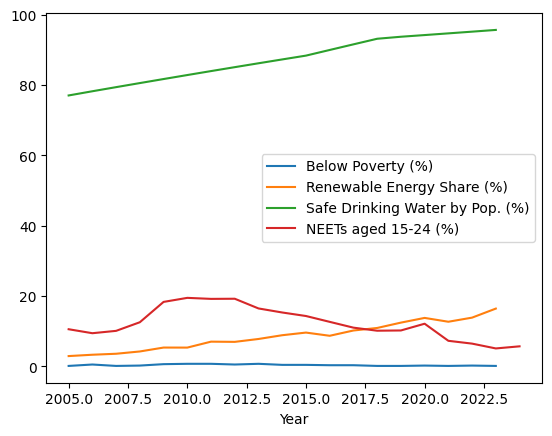

In [21]:
_ = df.plot()	# Not great

[Matplotlib](https://matplotlib.org/) is a wonderful data visualisation package built on top of NumPy.

`pandas` is built on top of `Matplotlib`, and one can easily interact via `df.plot(...)`. 

I personally like to work directly with `Matplotlib`.

Let's look at all of the data we have here between 2005 and 2023.

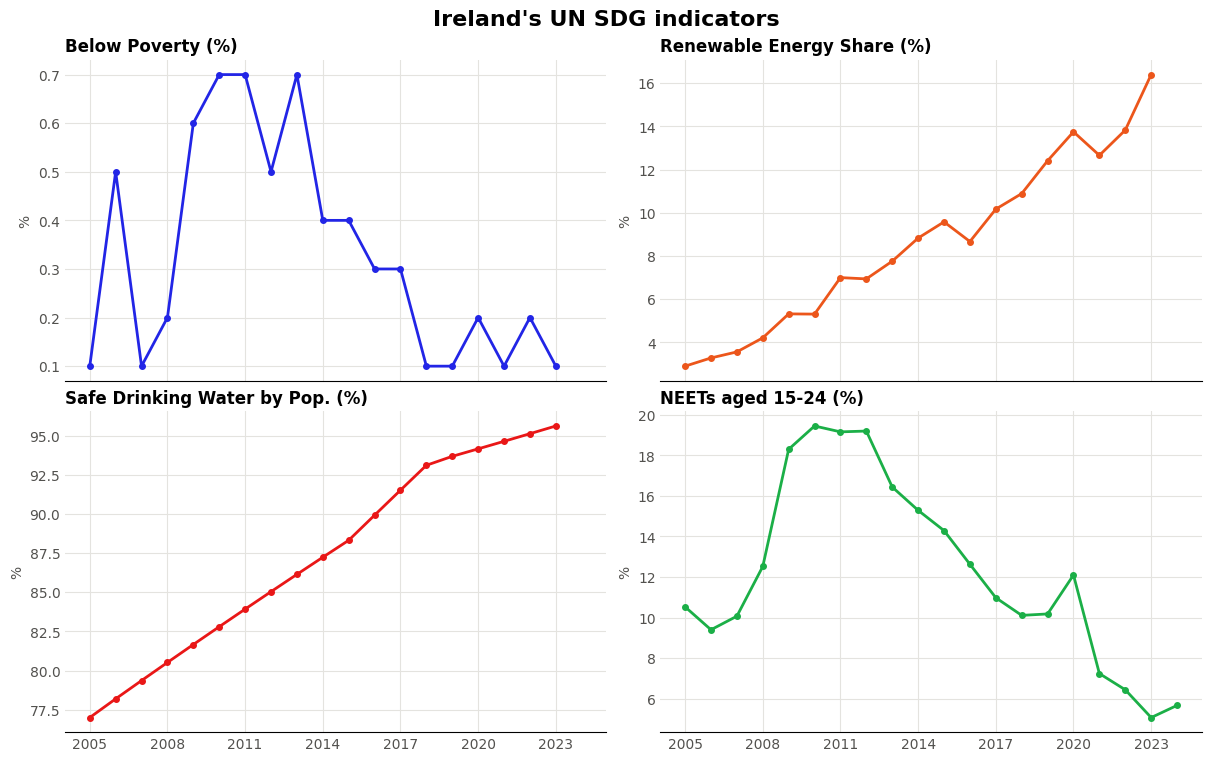

In [22]:
import matplotlib.pyplot as plt

COLOURS = ["#2225e6", "#ec561b", "#e91717", "#1baf47"]	
MUTED = "#52514e"		# secondary text
GRID = "#e4e3df"		# faint gridlines

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, layout="constrained")
fig.suptitle("Ireland's UN SDG indicators", fontsize=16, fontweight="bold")

for ax, col, colour in zip(axes.flat, df.columns, COLOURS):
	s = df[col]
	ax.plot(s.index, s.values, color=colour, linewidth=2, marker="o", markersize=4)

	# Random settings to change the appearance. 
	ax.set_title(col, loc="left", fontsize=12, fontweight="bold")
	ax.grid(color=GRID, linewidth=0.8)	# horizontal and vertical gridlines
	ax.set_axisbelow(True)
	ax.spines[["top", "right", "left"]].set_visible(False)
	ax.tick_params(colors=MUTED, length=0)
	ax.set_ylabel("%", color=MUTED)
	ax.set_xticks(range(2005, 2024, 3))	# 2005, 2008, ..., 2023

plt.show()

## Data for all countries

In [23]:
df1 = pd.read_excel("data/Goal1.xlsx")
df6 = pd.read_excel("data/Goal6.xlsx")
df7 = pd.read_excel("data/Goal7.xlsx")
df8 = pd.read_excel("data/Goal8.xlsx")

## How does Ireland compare?

These files hold the same four indicators as before, but for (almost) every country. Each file also mixes several breakdowns (by age, sex, urban/rural, ...), so we keep only the rows that match what we used for Ireland.

We write a small function to do the filtering, then glue the four results together side by side, just like we did with `pd.concat` earlier. The index now has *two* levels: `Country` and `Year`.

In [24]:
def extract(data, name, **filters):
	for column, value in filters.items():
		data = data[data[column] == value]
	s = data.set_index(["GeoAreaName", "TimePeriod"])["Value"]
	s.index.names = ["Country", "Year"]
	return s.rename(name)

Now we'll use `extract` to get all the data we need.

In [25]:
world = pd.concat([
	extract(df1, "Below Poverty (%)", SeriesCode="SI_POV_DAY1", Age="ALLAGE", Location="ALLAREA", Sex="BOTHSEX"),
	extract(df7, "Renewable Energy Share (%)"),
	extract(df6, "Safe Drinking Water by Pop. (%)", Location="ALLAREA"),
	extract(df8, "NEETs aged 15-24 (%)", SeriesCode="SL_TLF_NEET", Sex="BOTHSEX"),
], axis=1).sort_index()
world

Below Poverty (%)  Renewable Energy Share (%)  \
Country     Year                                                  
Afghanistan 2005                NaN                       33.88   
            2006                NaN                       31.89   
            2007                NaN                       28.78   
            2008                NaN                       21.17   
            2009                NaN                       16.53   
...                             ...                         ...   
Zimbabwe    2020                NaN                       64.20   
            2021                NaN                       62.03   
            2022                NaN                       58.01   
            2023                NaN                       54.64   
            2024                NaN                         NaN   

                  Safe Drinking Water by Pop. (%)  NEETs aged 15-24 (%)  
Country     Year                                                         
Afghanistan 2005                        14.726554                   NaN  
            2006                        15.542417                   NaN  
            2007                        16.650249                   NaN  
            2008                        17.554295                   NaN  
            2009                        18.389793                   NaN  
...                                           ...                   ...  
Zimbabwe    2020                        26.200596                   NaN  
            2021                        26.021851                 30.43  
            2022                        25.823425                 32.24  
            2023                        25.636070                 29.98  
            2024                        25.460564                 35.99  

[4649 rows x 4 columns]

Sanity check: the rows for Ireland should match our `df` from earlier.

In [26]:
world.loc["Ireland"]

,Below Poverty (%),Renewable Energy Share (%),Safe Drinking Water by Pop. (%),NEETs aged 15-24 (%)
Year,,,,
2005,0.1,2.90,76.994415,10.53
2006,0.5,3.28,78.189987,9.40
2007,0.1,3.56,79.358139,10.07
2008,0.2,4.21,80.515526,12.52
2009,0.6,5.32,81.662399,18.30
2010,0.7,5.31,82.798592,19.45
2011,0.7,7.00,83.924301,19.16
2012,0.5,6.94,85.039505,19.20
2013,0.7,7.76,86.144142,16.44


Next, the groups we compare against. Ireland is left out of each list, so it is compared with its *peers*.

- **EU**: the other 26 member states.
- **Island nations**: other island countries that are small or mid-sized, by population or by land area.
- **Small advanced economies**: the countries in the Small Advanced Economies Initiative, which Ireland belongs to.
- **World**: every other country in the data.

The lists are only a starting point. Try adding or removing countries.

In [27]:
groups = {
	"EU": [
		"Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czechia", "Denmark",
		"Estonia", "Finland", "France", "Germany", "Greece", "Hungary", "Italy",
		"Latvia", "Lithuania", "Luxembourg", "Malta", "Netherlands (Kingdom of the)",
		"Poland", "Portugal", "Romania", "Slovakia", "Slovenia", "Spain", "Sweden",
	],
	"Island nations": [
		"Cyprus", "Fiji", "Iceland", "Jamaica", "Malta", "Mauritius",
		"New Zealand", "Singapore", "Sri Lanka", "Trinidad and Tobago",
	],
	"Small advanced economies": [
		"Denmark", "Finland", "Israel", "New Zealand", "Singapore", "Switzerland",
	],
	"World": list(world.index.unique("Country").drop("Ireland")),
}

Countries report in different years, so we take a *snapshot*: each country's most recent value from 2018–2023.

`groupby("Country").last()` does exactly this. Within each country it takes the last value in each column, skipping any `NaN`s.

In [28]:
latest = world.query("2018 <= Year <= 2023").groupby("Country").last()
latest

,Below Poverty (%),Renewable Energy Share (%),Safe Drinking Water by Pop. (%),NEETs aged 15-24 (%)
Country,,,,
Afghanistan,NaN,17.89,29.907448,43.77
Albania,0.3,45.57,70.765396,23.16
Algeria,NaN,0.13,68.967865,NaN
American Samoa,NaN,0.30,90.538338,NaN
Andorra,NaN,18.32,90.639999,NaN
...,...,...,...,...
Viet Nam,1.6,24.49,58.074856,10.82
Wallis and Futuna Islands,NaN,6.18,68.899315,20.22
Yemen,NaN,2.21,NaN,NaN


Now for each group and indicator we work out:
- the group's median,
- Ireland's rank within the group, plus Ireland (1 = best).

For poverty and NEETs, *lower* is better, so we rank in ascending order for those.

In [29]:
lower_is_better = ["Below Poverty (%)", "NEETs aged 15-24 (%)"]

rows = []
for group, peers in groups.items():
	table = latest.loc[latest.index.isin(peers + ["Ireland"])]
	for indicator in latest.columns:
		values = table[indicator].dropna()
		rank = values.rank(ascending=indicator in lower_is_better, method="min")
		rows.append({
			"Indicator": indicator,
			"Group": group,
			"Ireland": values["Ireland"],
			"Group median": values.drop("Ireland").median(),
			"Ireland's rank": f"{rank['Ireland']:.0f} of {len(values)}",
		})

summary = pd.DataFrame(rows).set_index(["Indicator", "Group"])
summary.round(1)

,,Ireland,Group median,Ireland's rank
Indicator,Group,,,
Below Poverty (%),EU,0.1,0.4,4 of 26
Renewable Energy Share (%),EU,16.4,22.3,22 of 27
Safe Drinking Water by Pop. (%),EU,95.6,99.5,23 of 27
NEETs aged 15-24 (%),EU,5.1,9.2,2 of 27
Below Poverty (%),Island nations,0.1,0.9,2 of 7
Renewable Energy Share (%),Island nations,16.4,12.9,5 of 11
Safe Drinking Water by Pop. (%),Island nations,95.6,99.8,6 of 9
NEETs aged 15-24 (%),Island nations,5.1,13.6,1 of 10
Below Poverty (%),Small advanced economies,0.1,0.3,1 of 5


The same comparison as a picture. Each grey dot is a country, the dark bar is the group median, and the blue dot is Ireland.

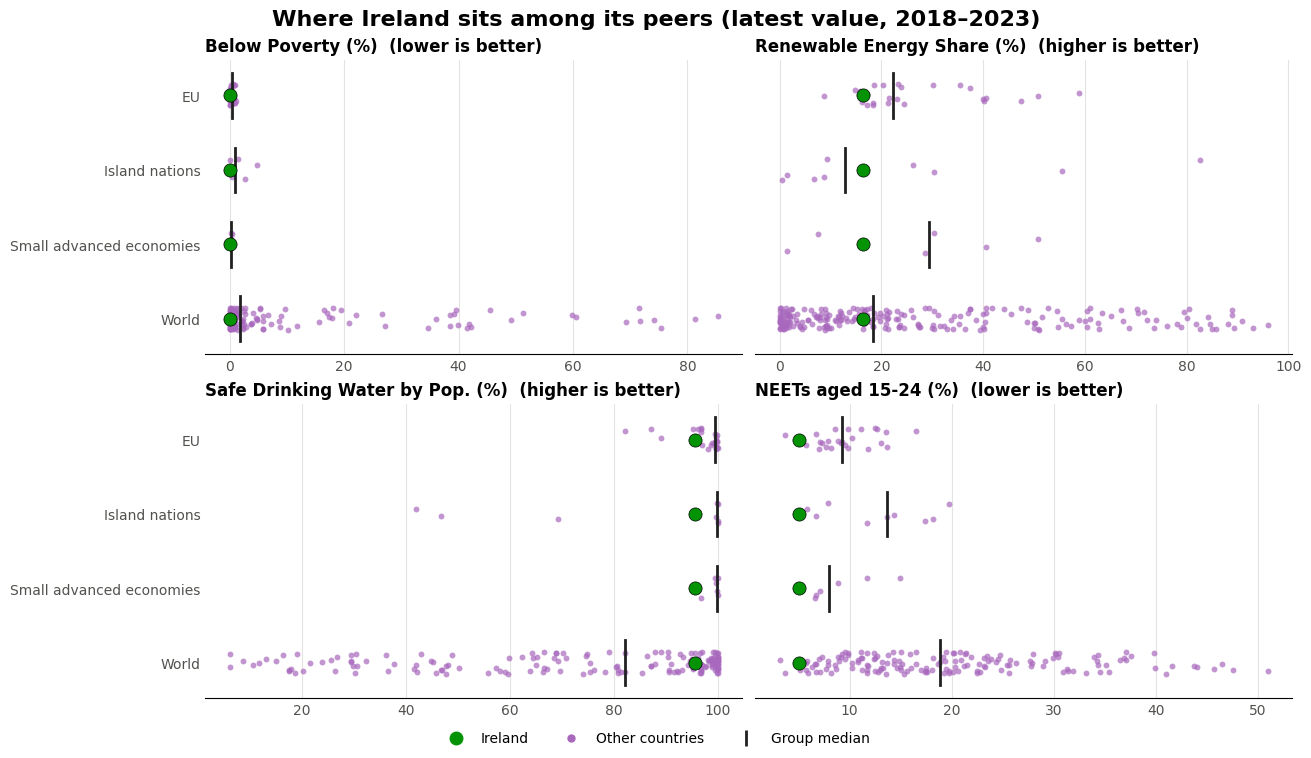

In [32]:
import numpy as np

IRELAND = "#039305"		# Ireland's highlight colour
OTHERS = "#A868BD"			# every other country
MEDIAN = "#202021"			# secondary text
MUTED = "#52514e"			# secondary text
GRID = "#e4e3df"			# faint gridlines

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharey=True, layout="constrained")
fig.suptitle("Where Ireland sits among its peers (latest value, 2018–2023)", fontsize=16, fontweight="bold")

for ax, indicator in zip(axes.flat, latest.columns):
	for row, (group, peers) in enumerate(groups.items()):
		values = latest.loc[latest.index.isin(peers), indicator].dropna()
		# One grey dot per country, nudged up/down a little so they don't all overlap
		jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(values))
		ax.scatter(values, row + jitter, s=18, color=OTHERS, alpha=0.7, linewidths=0)
		ax.plot([values.median()] * 2, [row - 0.3, row + 0.3], color=MEDIAN, linewidth=2)	# group median
		ax.scatter(latest.loc["Ireland", indicator], row, s=90, color=IRELAND, edgecolors="black", linewidths=0.5, zorder=3)

	arrow = "lower is better" if indicator in lower_is_better else "higher is better"
	ax.set_title(f"{indicator}  ({arrow})", loc="left", fontsize=12, fontweight="bold")
	ax.set_yticks(range(len(groups)), groups.keys())
	ax.grid(axis="x", color=GRID, linewidth=0.8)
	ax.set_axisbelow(True)
	ax.spines[["top", "right", "left"]].set_visible(False)
	ax.tick_params(colors=MUTED, length=0)

axes[0, 0].invert_yaxis()		# first group at the top (y-axis is shared, so flip it once)

# A legend built by hand, since the same three marks repeat in every panel
fig.legend(
	handles=[
		plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=IRELAND, label="Ireland"),
		plt.Line2D([], [], marker="o", linestyle="", markersize=5, color=OTHERS, label="Other countries"),
		plt.Line2D([], [], marker="|", linestyle="", markersize=12, markeredgewidth=2, color=MEDIAN, label="Group median"),
	],
	loc="outside lower center", ncols=3, frameon=False,
)
plt.show()

## Renewable energy across Europe

Let's zoom in on one indicator: the share of final energy consumption that comes from renewables.

**Question:** which European countries have made the most progress since 2005, and where does Ireland fit?

We start from `world` again and keep only European countries (micro-states like Andorra and Liechtenstein are left out).

In [33]:
europe = groups["EU"] + [
	"Ireland", "United Kingdom of Great Britain and Northern Ireland",
	"Iceland", "Norway", "Switzerland",
	"Albania", "Bosnia and Herzegovina", "Kosovo", "Montenegro", "North Macedonia", "Serbia",
	"Belarus", "Republic of Moldova", "Ukraine",
]

`world` is *long*: one row per (country, year). To compare years side by side we want it *wide*: one row per country and one column per year.

`unstack("Year")` does this by moving the `Year` level of the index into the columns. Some years have no European data at all, so we drop columns that are entirely `NaN`.

In [34]:
renewables = (world
	.loc[europe, "Renewable Energy Share (%)"]		# European rows, one column
	.unstack("Year")								# Year index level -> columns
	.dropna(axis=1, how="all")						# drop years with no data
	.rename(index={
		"United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
		"Netherlands (Kingdom of the)": "Netherlands",
	})
)
renewables

Year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Country,,,,,,,,,,,,,,,,,,,
Austria,24.41,26.64,28.99,29.68,31.31,31.15,31.64,34.37,34.58,35.67,34.82,34.63,33.98,34.09,33.99,35.78,36.50,37.13,39.95
Belgium,2.48,2.88,3.43,3.98,4.92,6.25,6.71,7.68,8.25,9.12,9.39,9.20,9.65,10.63,10.24,12.39,11.76,13.23,14.82
Bulgaria,9.83,9.96,8.85,9.94,11.62,14.27,13.22,15.61,18.25,17.15,17.85,17.71,17.11,19.59,19.30,21.10,20.41,19.82,20.28
Croatia,26.80,25.51,22.66,24.15,27.16,29.76,27.17,29.41,32.83,33.61,33.09,31.83,29.79,32.83,31.61,32.37,34.07,30.63,30.21
Cyprus,3.34,3.50,4.32,5.66,6.29,6.50,7.60,8.60,9.73,9.49,10.41,10.27,10.94,12.02,11.97,15.02,15.58,15.83,16.30
Czechia,7.53,7.88,8.32,8.99,10.25,10.95,12.16,12.80,13.95,14.85,14.83,14.77,14.46,14.71,15.87,16.96,17.10,17.08,17.23
Denmark,16.12,15.26,17.69,18.54,19.33,21.20,23.83,26.93,27.05,30.19,32.54,31.96,35.03,34.54,37.28,39.38,39.37,38.87,40.59
Estonia,18.90,17.22,18.65,20.54,24.21,25.32,25.16,24.96,24.47,25.29,28.17,27.23,27.52,28.56,31.21,40.28,37.77,37.01,40.14
Finland,31.68,31.40,31.91,34.76,32.54,33.58,35.29,38.87,38.68,41.41,43.40,42.53,44.51,44.45,45.59,47.51,50.44,49.69,50.76


Now the computation. We compare 2005 with 2023 in two ways:
- **Points gained** is the absolute change, 2023 − 2005, in percentage points.
- **Growth factor** is the relative change, 2023 ÷ 2005. A value of 3 means the share tripled.

Each column is a NumPy array, so each measure takes one line of arithmetic and no loops.

In [35]:
progress = pd.DataFrame({
	"2005": renewables[2005],
	"2023": renewables[2023],
})
progress["Points gained"] = progress["2023"] - progress["2005"]
progress["Growth factor"] = progress["2023"] / progress["2005"]
progress = progress.sort_values("Points gained", ascending=False)
progress.round(1)

,2005,2023,Points gained,Growth factor
Country,,,,
Denmark,16.1,40.6,24.5,2.5
Luxembourg,1.9,24.4,22.5,13.0
Estonia,18.9,40.1,21.2,2.1
Lithuania,17.5,37.5,20.0,2.1
Iceland,62.7,82.7,20.0,1.3
Bosnia and Herzegovina,19.7,39.5,19.7,2.0
Sweden,39.3,58.9,19.6,1.5
Republic of Moldova,4.3,23.6,19.4,5.5
Finland,31.7,50.8,19.1,1.6


The two measures tell different stories. `rank` turns each column into positions (1 = most progress).

In [36]:
ranks = progress[["Points gained", "Growth factor"]].rank(ascending=False).astype(int)
ranks.loc[["Ireland", "Malta", "Norway", "Montenegro"]]

,Points gained,Growth factor
Country,,
Ireland,16,7
Malta,32,1
Norway,36,37
Montenegro,40,40


- **Ireland** is mid-table on points gained (16th of 40) but 7th on growth: its share grew more than fivefold, from a very low base.
- **Malta** is 1st on growth because it started at 0.14%. A tiny starting value makes a ratio look huge. This is a common way relative change misleads.
- **Norway** is near the bottom on both, but it was already at about 60% in 2005, so there was little room to grow.
- **Montenegro** is one of only two countries whose share *fell*.

Which measure is "right" depends on the question you are asking.

A *dumbbell chart* shows both years at once: a grey dot for 2005, a coloured dot for 2023, and a line joining them. Countries are sorted by their 2023 share.

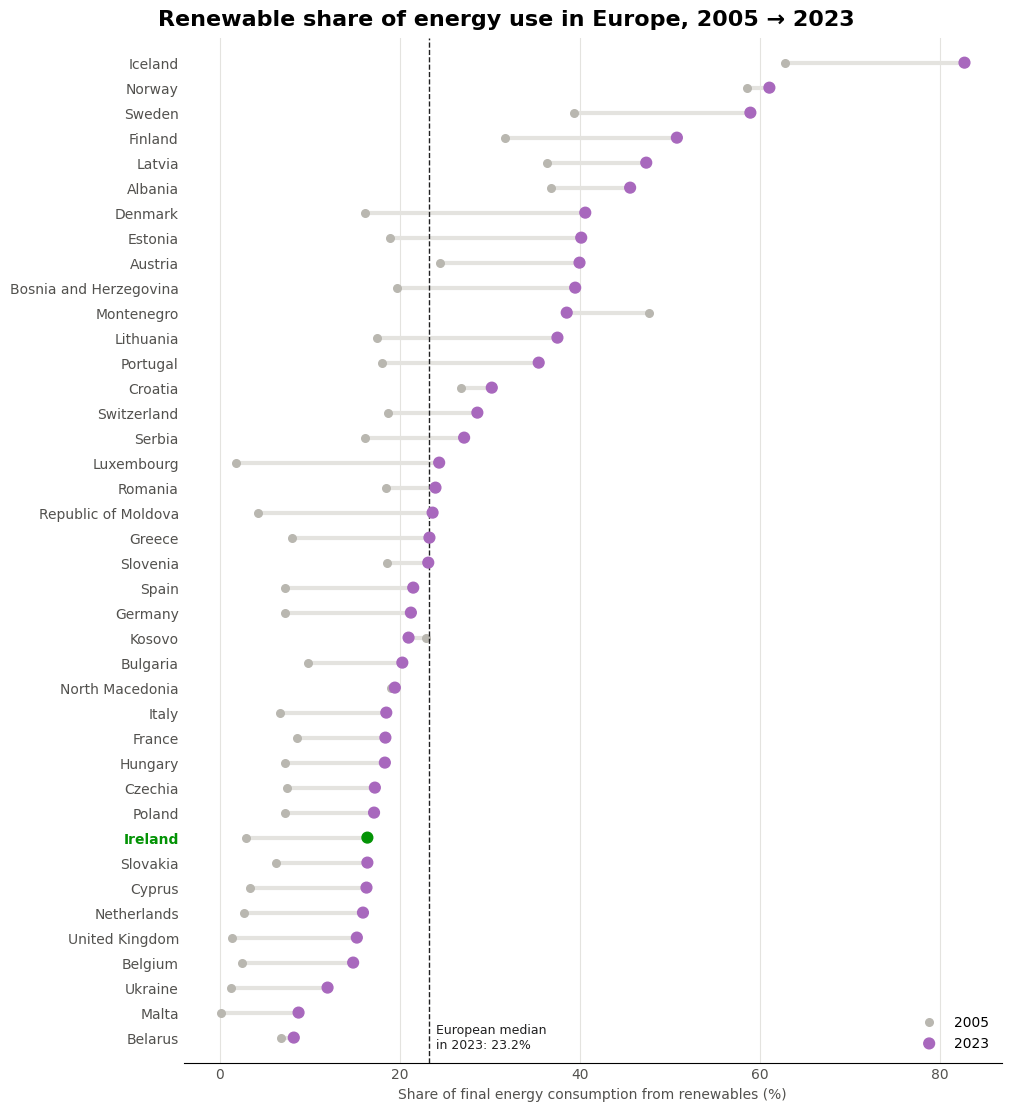

In [37]:
progress = progress.sort_values("2023")		# lowest share at the bottom of the chart
median_2023 = progress["2023"].median()
EARLY = "#b9b7b0"		# colour of the 2005 dots

fig, ax = plt.subplots(figsize=(10, 11), layout="constrained")
fig.suptitle("Renewable share of energy use in Europe, 2005 → 2023", fontsize=16, fontweight="bold")

y = range(len(progress))
colours = [IRELAND if c == "Ireland" else OTHERS for c in progress.index]
ax.hlines(y, progress["2005"], progress["2023"], color=GRID, linewidth=3, zorder=1)	# the bar of each dumbbell
ax.scatter(progress["2005"], y, s=30, color=EARLY, zorder=2, label="2005")
ax.scatter(progress["2023"], y, s=60, color=colours, zorder=3, label="2023")
ax.axvline(median_2023, color=MEDIAN, linestyle="--", linewidth=1)
ax.text(median_2023 + 0.8, 0, f"European median\nin 2023: {median_2023:.1f}%", color=MEDIAN, fontsize=9, va="center")

ax.set_yticks(y, progress.index)
ax.set_ylim(-1, len(progress))
ax.set_xlabel("Share of final energy consumption from renewables (%)", color=MUTED)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
ax.legend(loc="lower right", frameon=False)

# Make Ireland's label stand out (after tick_params, which would reset the colour)
for label in ax.get_yticklabels():
	if label.get_text() == "Ireland":
		label.set_color(IRELAND)
		label.set_fontweight("bold")

plt.show()